# Project A — CNN from Scratch: CIFAR-10 Image Classifier
**Subject:** Deep Learning · Practical Report 4 (PR 4)  
**Framework:** TensorFlow / Keras · Python 3.x  
**Dataset:** CIFAR-10 (50,000 training images, 10,000 test images)  
**Tasks covered:** A1–A6 — loading/EDA, convolution, padding/strides, pooling/flatten, LeNet-5 and custom CNN, backpropagation/training, augmentation, transfer learning, and residual connections.

## 0. Setup and configuration

In [1]:
# If needed, uncomment and run this once:
# %pip install tensorflow matplotlib seaborn scikit-learn pandas numpy

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

# Change these settings depending on the available hardware.
QUICK_RUN = True
EPOCHS = 2                   # Quick mode: only 2 epochs
BATCH_SIZE = 64
if QUICK_RUN:
    EPOCHS = 2
    BATCH_SIZE = 64

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

TensorFlow: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## Task A1 — Data Loading, EDA & Preprocessing

### A1.1 Load CIFAR-10

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)
print("Image dtype:", X_train.dtype)
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Unique labels:", np.unique(y_train).ravel())

# Quick mode uses a smaller subset so the notebook runs faster.
if QUICK_RUN:
    X_train, y_train = X_train[:10000], y_train[:10000]
    X_test, y_test = X_test[:2000], y_test[:2000]
    print("QUICK_RUN enabled: using 10,000 training and 2,000 test images.")

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape:  (10000, 32, 32, 3)
y_test shape:  (10000, 1)
Image dtype: uint8
Pixel range: 0 to 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]
QUICK_RUN enabled: using 10,000 training and 2,000 test images.


### A1.2 Visualise 10 sample images — one per class

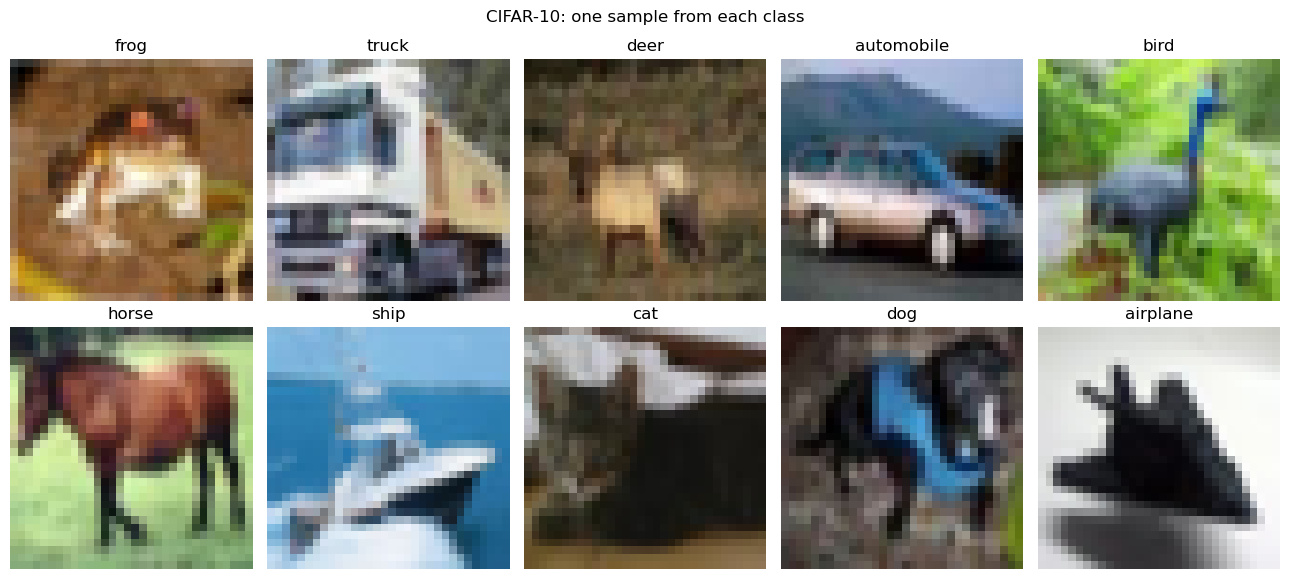

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
shown = set()
for ax in axes.flat:
    # Select an example from a class not yet shown
    idx = next(i for i, label in enumerate(y_train.ravel()) if label not in shown)
    label = int(y_train[idx, 0])
    shown.add(label)
    ax.imshow(X_train[idx])
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.suptitle("CIFAR-10: one sample from each class")
plt.tight_layout()
plt.show()

**Observation:** CIFAR-10 images are small 32×32 RGB images. Several classes (for example, cats vs dogs and automobiles vs trucks) can look similar at this resolution, so spatial features are important.

### A1.3 Pixel distribution before and after normalisation

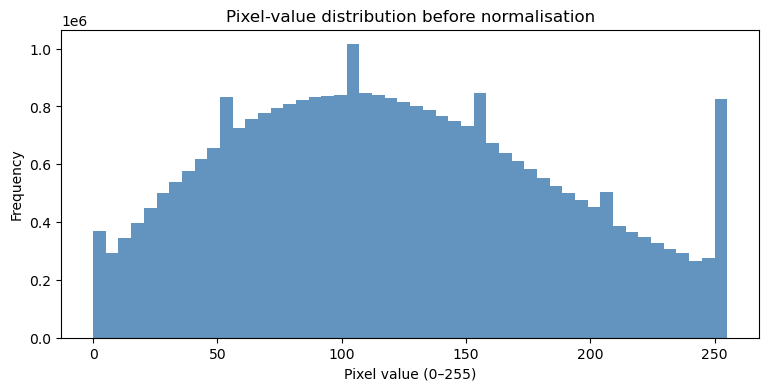

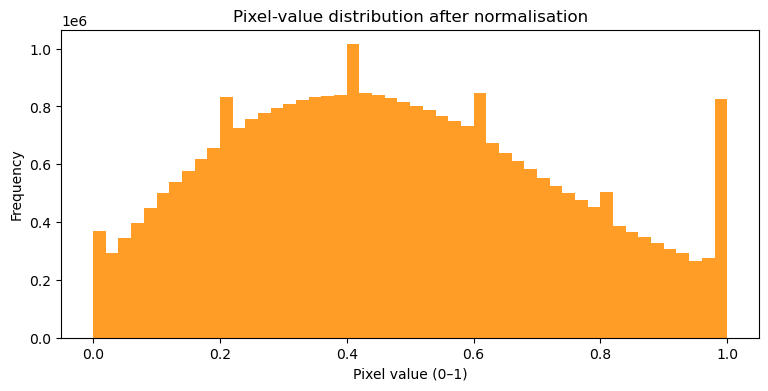

Normalised range: 0.0 to 1.0


In [4]:
plt.figure(figsize=(9, 4))
plt.hist(X_train.flatten(), bins=50, color="steelblue", alpha=0.85)
plt.title("Pixel-value distribution before normalisation")
plt.xlabel("Pixel value (0–255)")
plt.ylabel("Frequency")
plt.show()

# Normalise pixels to [0, 1], a common input range for neural networks.
X_train_norm = X_train.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

plt.figure(figsize=(9, 4))
plt.hist(X_train_norm.flatten(), bins=50, color="darkorange", alpha=0.85)
plt.title("Pixel-value distribution after normalisation")
plt.xlabel("Pixel value (0–1)")
plt.ylabel("Frequency")
plt.show()

print("Normalised range:", X_train_norm.min(), "to", X_train_norm.max())

**Observation:** Dividing by 255 rescales pixel values from 0–255 to 0–1. This keeps input magnitudes smaller and generally helps optimisation behave more consistently.

### A1.4 One-hot encode labels

In [5]:
y_train_int = y_train.ravel()
y_test_int = y_test.ravel()

y_train_onehot = to_categorical(y_train_int, num_classes=10)
y_test_onehot = to_categorical(y_test_int, num_classes=10)

print("Integer label example:", y_train_int[0])
print("One-hot label example:", y_train_onehot[0])
print("One-hot label shape:", y_train_onehot.shape)
print("Sum of first one-hot vector:", y_train_onehot[0].sum())

Integer label example: 6
One-hot label example: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
One-hot label shape: (10000, 10)
Sum of first one-hot vector: 1.0


### A1.5 CNN vs ANN — markdown answer
- **ANN / MLP:** Typically flattens an image into one long vector. Flattening removes the explicit 2-D neighbourhood structure; a dense layer connects each input value to many neurons and can require many parameters.
- **CNN:** Uses learnable filters that slide across the image. The same filter weights are shared at different positions, allowing the network to detect local patterns such as edges, textures and shapes with fewer parameters.
- **Why CNN for images?** Local connectivity and weight sharing preserve useful spatial structure and make convolutional networks a natural fit for image classification.

## Task A2 — Convolution Operation, Padding & Strides

### A2.1 Manual convolution demo on a grayscale image

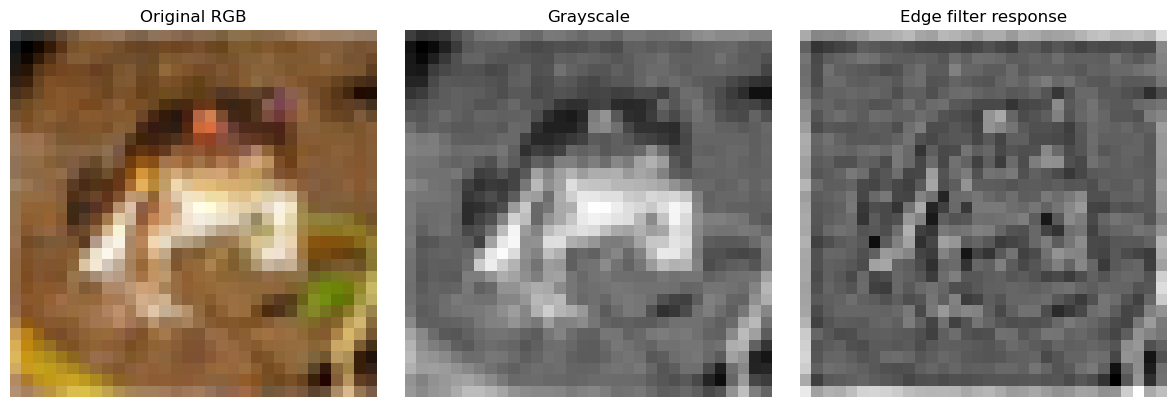

Kernel used:
 [[-1. -1. -1.]
 [-1.  8. -1.]
 [-1. -1. -1.]]


In [6]:
# Display one image in grayscale, then apply a 3x3 edge-detection filter.
sample_rgb = X_train[0]
sample_gray = tf.image.rgb_to_grayscale(sample_rgb).numpy().squeeze()

edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

manual_input = sample_gray.astype(np.float32)[None, :, :, None]
manual_filter = edge_kernel[:, :, None, None]
manual_edges = tf.nn.conv2d(
    manual_input, filters=manual_filter, strides=1, padding="SAME"
).numpy()[0, :, :, 0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sample_rgb); axes[0].set_title("Original RGB")
axes[1].imshow(sample_gray, cmap="gray"); axes[1].set_title("Grayscale")
axes[2].imshow(manual_edges, cmap="gray"); axes[2].set_title("Edge filter response")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Kernel used:\n", edge_kernel)

**Explanation:** A convolution computes weighted sums over small local patches. The edge filter responds strongly where neighbouring pixel intensities change. With a stride of 1, the filter shifts one pixel at a time; `SAME` padding preserves the input height and width for stride 1.

### A2.2 VALID vs SAME padding

In [7]:
test_image = X_train_norm[:1]
valid_layer = layers.Conv2D(3, (3, 3), strides=1, padding="valid")
same_layer = layers.Conv2D(3, (3, 3), strides=1, padding="same")

valid_out = valid_layer(test_image)
same_out = same_layer(test_image)
print("Input shape:", test_image.shape)
print("VALID output shape:", valid_out.shape)
print("SAME output shape: ", same_out.shape)

Input shape: (1, 32, 32, 3)
VALID output shape: (1, 30, 30, 3)
SAME output shape:  (1, 32, 32, 3)


**Observation:** For a 32×32 input and 3×3 filter with stride 1, `VALID` produces 30×30 because no padding is added. `SAME` produces 32×32 because padding is added around the border.

### A2.3 Effect of strides

Stride=1 output: (1, 32, 32, 8)
Stride=2 output: (1, 16, 16, 8)


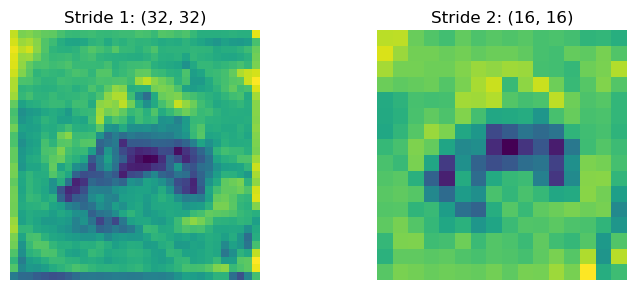

In [8]:
stride1_layer = layers.Conv2D(8, 3, strides=1, padding="same")
stride2_layer = layers.Conv2D(8, 3, strides=2, padding="same")
out_stride1 = stride1_layer(test_image)
out_stride2 = stride2_layer(test_image)
print("Stride=1 output:", out_stride1.shape)
print("Stride=2 output:", out_stride2.shape)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(out_stride1[0, :, :, 0], cmap="viridis")
axes[0].set_title(f"Stride 1: {out_stride1.shape[1:3]}")
axes[1].imshow(out_stride2[0, :, :, 0], cmap="viridis")
axes[1].set_title(f"Stride 2: {out_stride2.shape[1:3]}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

**Observation:** Stride 1 evaluates the filter at every adjacent position. Stride 2 moves two pixels at a time and reduces spatial dimensions, which is computationally cheaper but may discard some detail.

### A2.4 Build and visualise convolution feature maps

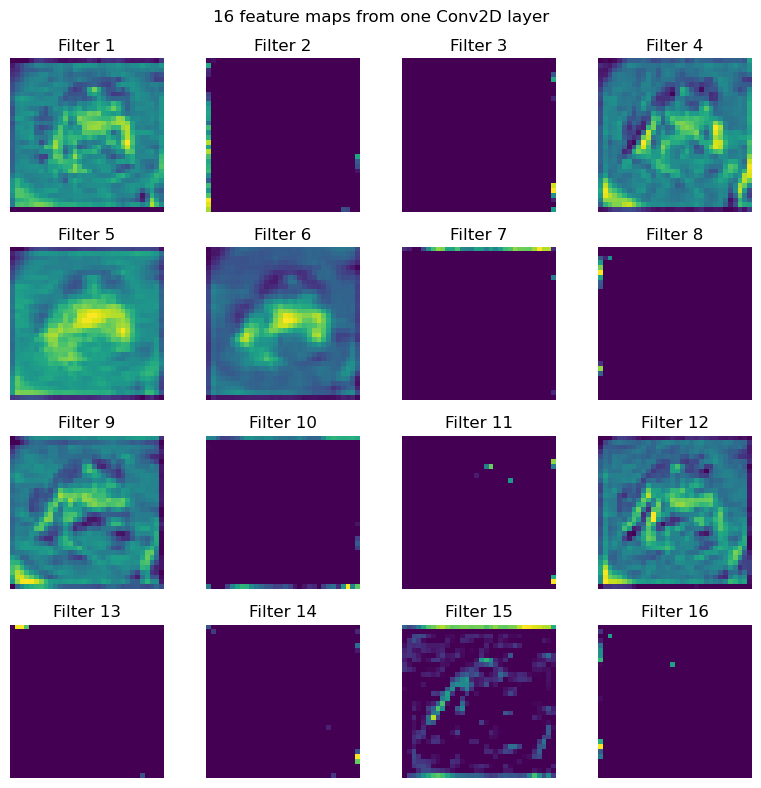

Feature map tensor shape: (1, 32, 32, 16)


In [9]:
feature_model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same")
])
feature_maps = feature_model.predict(X_train_norm[:1], verbose=0)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")
plt.suptitle("16 feature maps from one Conv2D layer")
plt.tight_layout(); plt.show()
print("Feature map tensor shape:", feature_maps.shape)

**Observation:** Early convolution filters can learn local edges, gradients and colour transitions. Later layers combine these low-level features into more complex patterns.

## Task A3 — Pooling, Flatten & CNN Architecture

### A3.1 MaxPooling vs AveragePooling

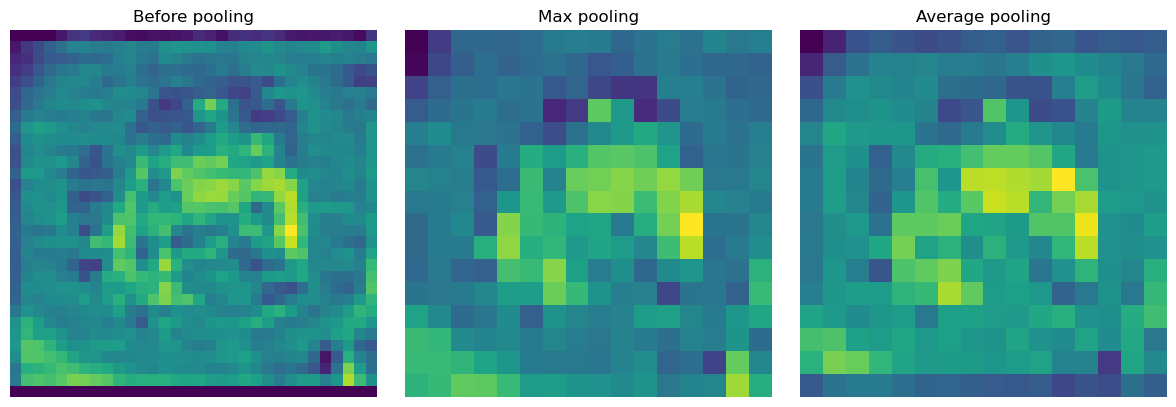

Before: (1, 32, 32, 16) Max: (1, 16, 16, 16) Average: (1, 16, 16, 16)


In [10]:
conv_for_pool = feature_model.predict(X_train_norm[:1], verbose=0)
max_pooled = layers.MaxPooling2D(pool_size=(2, 2))(conv_for_pool)
avg_pooled = layers.AveragePooling2D(pool_size=(2, 2))(conv_for_pool)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(conv_for_pool[0, :, :, 0], cmap="viridis")
axes[0].set_title("Before pooling")
axes[1].imshow(max_pooled[0, :, :, 0], cmap="viridis")
axes[1].set_title("Max pooling")
axes[2].imshow(avg_pooled[0, :, :, 0], cmap="viridis")
axes[2].set_title("Average pooling")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Before:", conv_for_pool.shape, "Max:", max_pooled.shape, "Average:", avg_pooled.shape)

**Observation:** A 2×2 pooling layer halves each spatial dimension. Max pooling keeps the strongest activation in each region, while average pooling keeps the mean. Max pooling often preserves prominent feature responses.

### A3.2 Flatten layer and output size

In [11]:
flatten_demo = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten()
])
flatten_output = flatten_demo.predict(X_train_norm[:1], verbose=0)
print("Input shape:", X_train_norm[:1].shape)
print("Flatten output shape:", flatten_output.shape)
print("Number of flattened features:", flatten_output.shape[1])

Input shape: (1, 32, 32, 3)
Flatten output shape: (1, 4096)
Number of flattened features: 4096


**Explanation:** Flatten converts the 3-D feature tensor (height × width × channels) into a 1-D vector per image. A following Dense layer uses this vector for classification. Flatten can create many parameters, so GlobalAveragePooling is often used in modern architectures to reduce model size.

### A3.3 LeNet-5-style architecture adapted for CIFAR-10

In [12]:
def build_lenet5_cifar():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(6, 5, activation="tanh", padding="same"),
        layers.AveragePooling2D(pool_size=2),
        layers.Conv2D(16, 5, activation="tanh"),
        layers.AveragePooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(120, activation="tanh"),
        layers.Dense(84, activation="tanh"),
        layers.Dense(10, activation="softmax")
    ], name="LeNet5_CIFAR10")
    return model

lenet_model = build_lenet5_cifar()
lenet_model.summary()

Model: "LeNet5_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 16, 16, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 6, 6, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        69,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,126 (324.71 KB)

 Trainable params: 83,126 (324.71 KB)

 Non-trainable params: 0 (0.00 B)

**Architecture note:** This is a LeNet-5-inspired adaptation for 32×32 RGB CIFAR-10. It uses convolution → average pooling → convolution → average pooling → flatten → dense layers. The original LeNet-5 was designed for grayscale digit images and used tanh/average pooling; modern CNNs commonly use ReLU and max pooling.

### A3.4 Build a custom CNN for CIFAR-10

In [13]:
def build_custom_cnn():
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="Custom_CIFAR10_CNN")

model_cnn = build_custom_cnn()
model_cnn.summary()
print("Custom CNN parameters:", model_cnn.count_params())

Model: "Custom_CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Custom CNN parameters: 175018


**Architecture explanation:** Two 32-filter convolutions learn low-level features, pooling reduces spatial size, 64-filter convolutions learn richer patterns, and a 128-filter layer learns higher-level features. GlobalAveragePooling2D reduces the feature tensor to a vector; Dense + softmax predicts the 10 classes.

## Task A4 — Backpropagation in CNN & Training

### A4.1 Backpropagation — markdown answer

1. **Forward pass:** The image moves through convolution, activation, pooling and dense layers to produce class probabilities.
2. **Loss:** Categorical cross-entropy compares predicted probabilities with the one-hot true label.
3. **Backward pass:** Automatic differentiation calculates gradients of the loss with respect to trainable weights using the chain rule.
4. **Weight update:** The optimiser (Adam here) updates weights in the direction that reduces loss.
5. **CNN-specific gradient flow:** Convolution gradients are accumulated across all positions that reuse a filter. Max-pooling sends gradient through the maximum location in each pooling region; average pooling distributes gradient across its region.
6. **Repeat:** Training performs this process for each batch and epoch. Validation data helps monitor generalisation and overfitting.

### A4.2 Compile and train the custom CNN

In [14]:
model_cnn.compile(
    optimizer=keras.optimizers.Adam(),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "best_custom_cnn.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1
    )
]

start_time = time.time()
history_cnn = model_cnn.fit(
    X_train_norm, y_train_onehot,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)
print(f"Training time: {(time.time() - start_time)/60:.1f} minutes")

Epoch 1/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.1809 - loss: 2.1151
Epoch 1: val_accuracy improved from None to 0.23900, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 25s 103ms/step - accuracy: 0.1809 - loss: 2.1151 - val_accuracy: 0.2390 - val_loss: 1.9237 - learning_rate: 0.0010
Epoch 2/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.2643 - loss: 1.8783
Epoch 2: val_accuracy improved from 0.23900 to 0.25100, saving model to best_custom_cnn.keras

Epoch 2: finished saving model to best_custom_cnn.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - accuracy: 0.2643 - loss: 1.8783 - val_accuracy: 0.2510 - val_loss: 1.8710 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.
Training time: 0.6 minutes


### A4.3 Plot training and validation curves

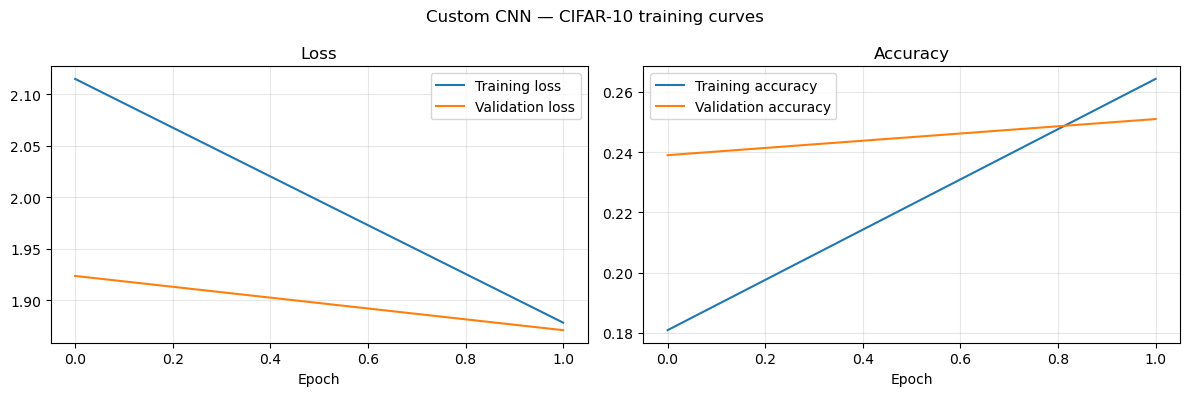

In [15]:
def plot_history(history, title="Training curves"):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["loss"], label="Training loss")
    axes[0].plot(hist["val_loss"], label="Validation loss")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(hist["accuracy"], label="Training accuracy")
    axes[1].plot(hist["val_accuracy"], label="Validation accuracy")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

plot_history(history_cnn, "Custom CNN — CIFAR-10 training curves")

**Interpretation guide:** Ideally, training and validation loss decrease while both accuracies increase. If training accuracy continues to rise but validation accuracy stalls or validation loss rises, the model may be overfitting. Dropout, data augmentation, and early stopping help reduce overfitting.

### A4.4 Evaluate and analyse the CNN

Custom CNN test loss: 1.8652
Custom CNN test accuracy: 27.7500%
              precision    recall  f1-score   support

    airplane       0.35      0.37      0.36       196
  automobile       0.53      0.30      0.38       198
        bird       0.22      0.55      0.31       195
         cat       0.29      0.04      0.06       199
        deer       0.19      0.32      0.24       198
         dog       0.00      0.00      0.00       185
        frog       0.23      0.18      0.20       216
       horse       0.24      0.39      0.30       193
        ship       0.36      0.53      0.43       217
       truck       0.57      0.08      0.15       203

    accuracy                           0.28      2000
   macro avg       0.30      0.28      0.24      2000
weighted avg       0.30      0.28      0.25      2000



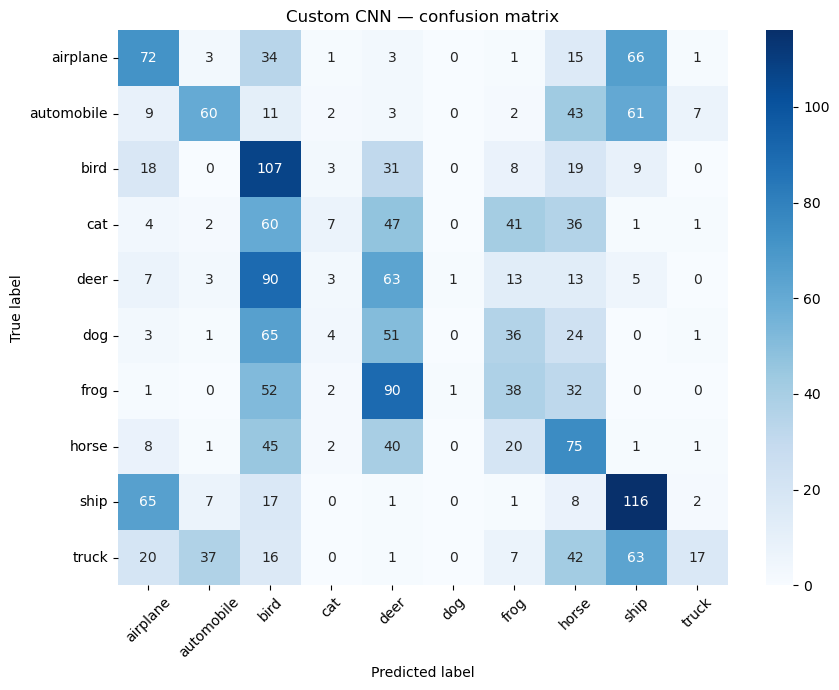

In [16]:
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test_norm, y_test_onehot, verbose=0)
print(f"Custom CNN test loss: {test_loss_cnn:.4f}")
print(f"Custom CNN test accuracy: {test_acc_cnn:.4%}")

pred_prob_cnn = model_cnn.predict(X_test_norm, batch_size=BATCH_SIZE, verbose=0)
pred_cnn = np.argmax(pred_prob_cnn, axis=1)
print(classification_report(y_test_int, pred_cnn, target_names=CLASS_NAMES, zero_division=0))

cm_cnn = confusion_matrix(y_test_int, pred_cnn)
plt.figure(figsize=(9, 7))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("Custom CNN — confusion matrix")
plt.xticks(rotation=45); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

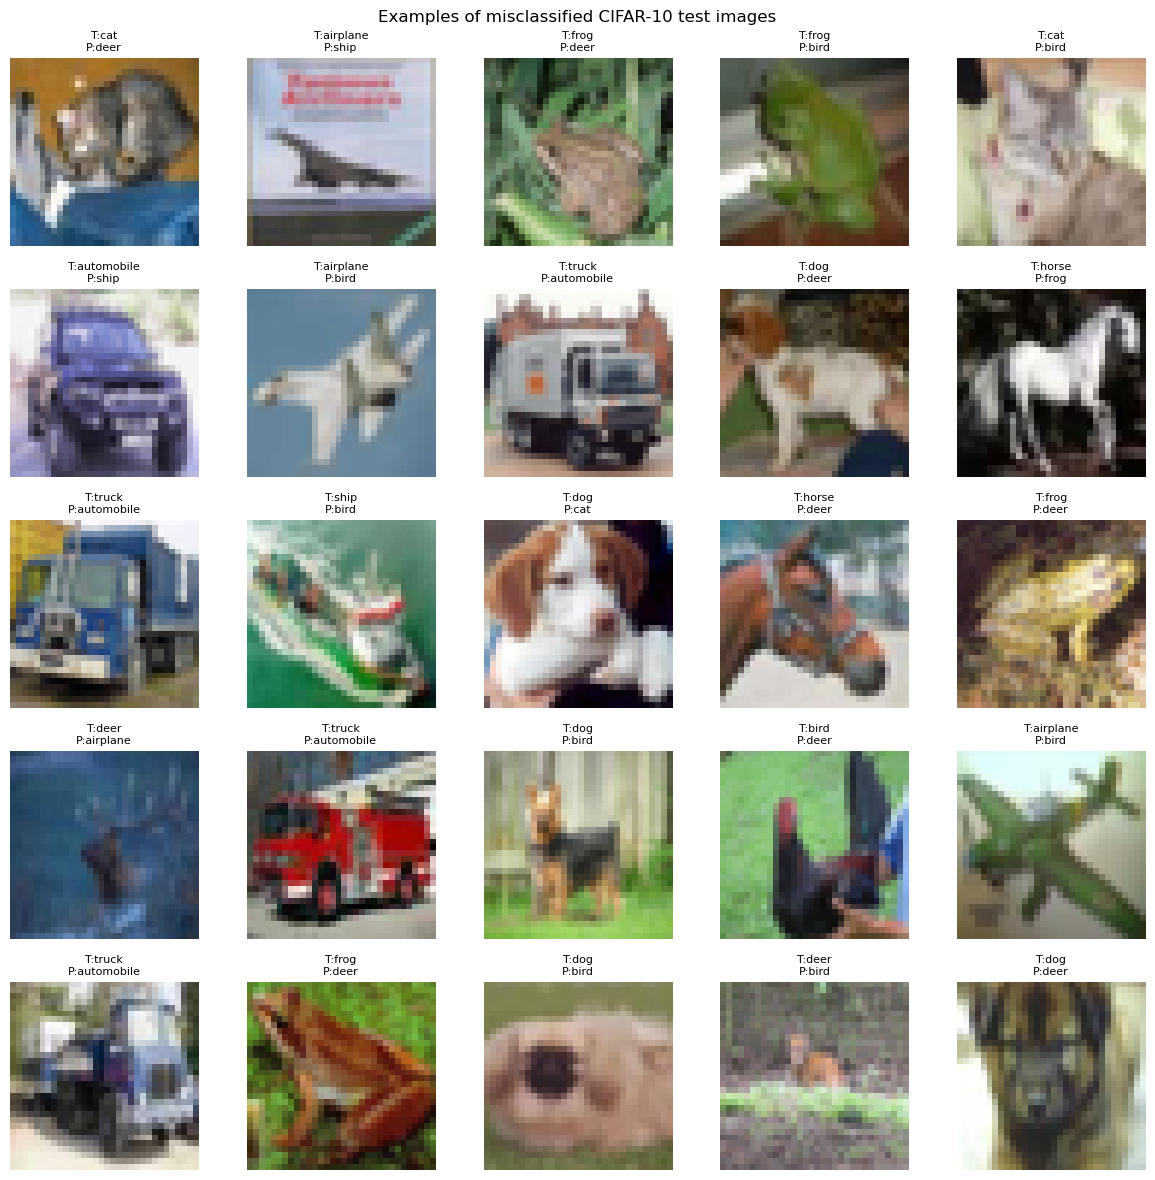

In [17]:
# Display up to 25 misclassified test images.
wrong = np.where(pred_cnn != y_test_int)[0]
n_show = min(25, len(wrong))
if n_show:
    fig, axes = plt.subplots(5, 5, figsize=(12, 12))
    for ax, idx in zip(axes.flat, wrong[:n_show]):
        ax.imshow(X_test[idx])
        ax.set_title(f"T:{CLASS_NAMES[y_test_int[idx]]}\nP:{CLASS_NAMES[pred_cnn[idx]]}", fontsize=8)
        ax.axis("off")
    for ax in axes.flat[n_show:]: ax.axis("off")
    plt.suptitle("Examples of misclassified CIFAR-10 test images")
    plt.tight_layout(); plt.show()

**Analysis:** The confusion matrix reveals which classes are confused most often. Similar-looking categories such as cat/dog or automobile/truck may be misclassified because CIFAR-10 images are only 32×32 pixels. Use the printed test accuracy and classification report as the measured results in the final report; do not substitute expected benchmark values.

## Task A5 — Data Augmentation

### A5.1 Why data augmentation? — markdown answer

Data augmentation creates realistic variations of training images (for example, horizontal flips and small translations). It does not create new labels; it increases the variety of examples seen during training, can reduce overfitting, and often improves generalisation. Augmentation is applied to training images only, not to validation/test images. It is especially useful when the labelled dataset is limited.

### A5.2 Apply augmentation using ImageDataGenerator

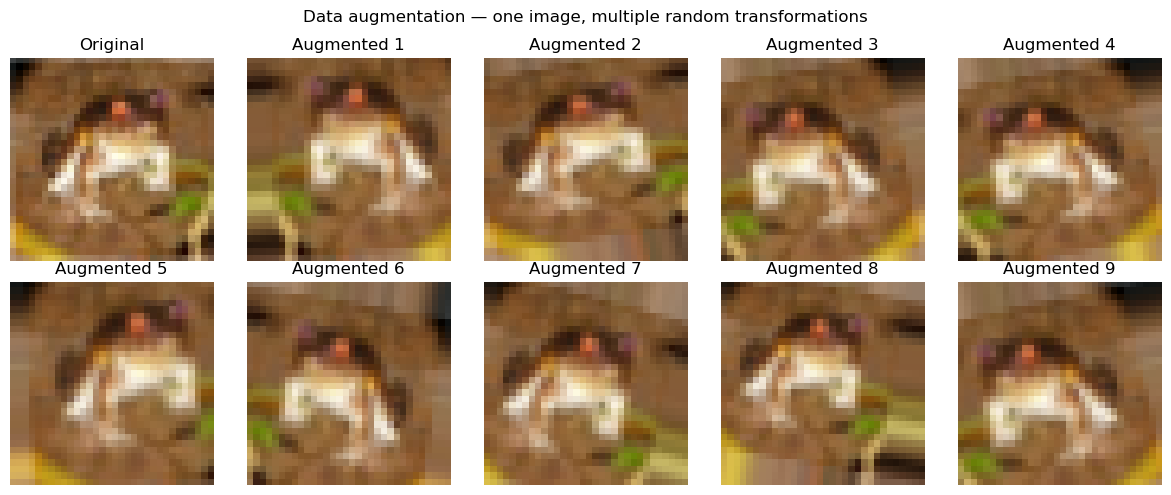

In [18]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)
datagen.fit(X_train_norm)

# Plot one original and 9 augmented versions of the same image.
source_img = X_train_norm[0:1]
aug_iter = datagen.flow(source_img, batch_size=1, shuffle=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(X_train[0]); axes[0, 0].set_title("Original"); axes[0, 0].axis("off")
for i in range(9):
    aug_img = next(aug_iter)[0]
    ax = axes.flat[i + 1]
    ax.imshow(np.clip(aug_img, 0, 1))
    ax.set_title(f"Augmented {i+1}")
    ax.axis("off")
plt.suptitle("Data augmentation — one image, multiple random transformations")
plt.tight_layout(); plt.show()

### A5.3 Retrain the CNN with augmentation

Epoch 1/2
156/156 ━━━━━━━━━━━━━━━━━━━━ 44s 214ms/step - accuracy: 0.1608 - loss: 2.1676 - val_accuracy: 0.2230 - val_loss: 2.0347 - learning_rate: 0.0010
Epoch 2/2
  1/156 ━━━━━━━━━━━━━━━━━━━━ 16s 106ms/step - accuracy: 0.1094 - loss: 2.0572

c:\Users\ishan\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.1094 - loss: 2.0572 - val_accuracy: 0.2210 - val_loss: 2.0536 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 1.
Augmented CNN test accuracy: 22.3000%


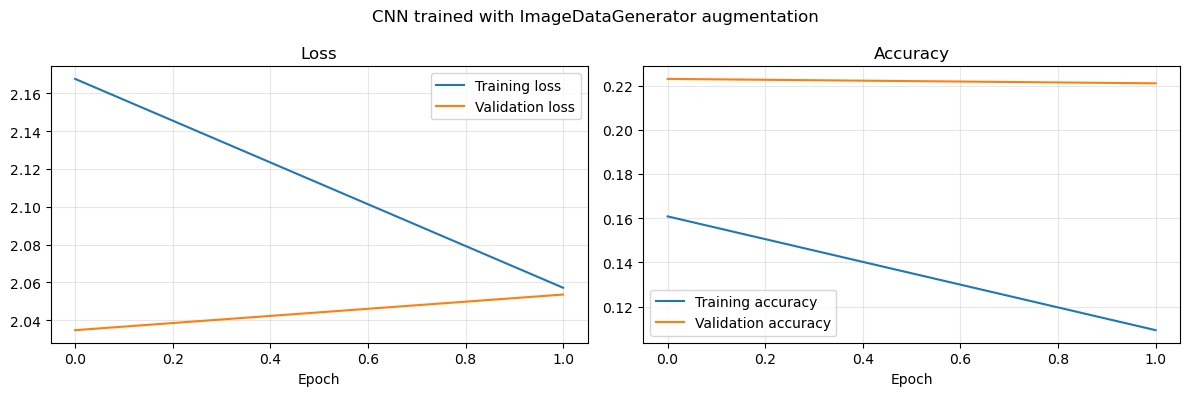

In [19]:
# Use the same architecture for a fair comparison.
model_aug = build_custom_cnn()
model_aug.compile(
    optimizer=keras.optimizers.Adam(),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
callbacks_aug = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=5, min_lr=1e-6, verbose=1)
]

history_aug = model_aug.fit(
    datagen.flow(X_train_norm, y_train_onehot, batch_size=BATCH_SIZE),
    epochs=EPOCHS,
    steps_per_epoch=len(X_train_norm) // BATCH_SIZE,
    validation_data=(X_test_norm, y_test_onehot),
    callbacks=callbacks_aug,
    verbose=1
)
test_loss_aug, test_acc_aug = model_aug.evaluate(X_test_norm, y_test_onehot, verbose=0)
print(f"Augmented CNN test accuracy: {test_acc_aug:.4%}")
plot_history(history_aug, "CNN trained with ImageDataGenerator augmentation")

**Comparison note:** Augmented training is usually harder, so training accuracy may be lower. A useful outcome is a smaller gap between training and validation performance and/or better test accuracy. Actual results depend on epochs, hardware, and random initialisation.

### A5.4 Modern augmentation with Keras preprocessing layers

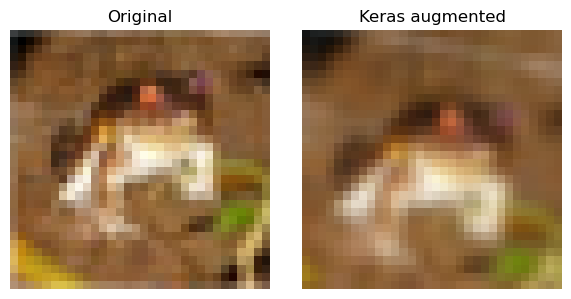

Model: "Modern_Augmented_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ keras_augmentation (Sequential) │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
keras_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
], name="keras_augmentation")

# Visualise modern Keras augmentation.
aug_preview = keras_augmentation(X_train_norm[:1], training=True).numpy()
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X_train_norm[0]); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(np.clip(aug_preview[0], 0, 1)); axes[1].set_title("Keras augmented"); axes[1].axis("off")
plt.tight_layout(); plt.show()

def build_modern_aug_cnn():
    inputs = keras.Input(shape=(32, 32, 3))
    x = keras_augmentation(inputs)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="Modern_Augmented_CNN")

model_modern_aug = build_modern_aug_cnn()
model_modern_aug.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model_modern_aug.summary()

**Note:** This model definition includes augmentation as part of the network. To train it, run the optional cell below. The augmentation layers are active during training and inactive during evaluation.

## Task A6 — Transfer Learning: Feature Extraction & Fine-Tuning

### A6.1 Why transfer learning? — markdown answer

Training a deep CNN from scratch requires substantial compute and many labelled examples. Transfer learning starts from a network pretrained on a large dataset (here, ImageNet). Early layers often learn general edges, textures and shapes that are useful for many image tasks.

- **Feature extraction:** Freeze the pretrained base and train a new classifier head. This is faster and uses fewer trainable parameters.
- **Fine-tuning:** Unfreeze some of the later pretrained layers and continue training at a very low learning rate. This can adapt higher-level features to CIFAR-10, but too high a learning rate can damage useful pretrained weights.

### A6.2 Feature extraction with MobileNetV2

In [22]:
# MobileNetV2 expects 96x96 or larger inputs. CIFAR-10 images are resized from 32x32 to 96x96.
# This step uses additional memory; if necessary, run on a GPU or use a smaller subset for a smoke test.
IMG_SIZE = 96

def resize_images(images, size=IMG_SIZE, batch_size=256):
    resized_chunks = []
    for start in range(0, len(images), batch_size):
        batch = tf.image.resize(images[start:start+batch_size], (size, size)).numpy()
        resized_chunks.append(batch.astype("float32"))
    return np.concatenate(resized_chunks, axis=0)

X_train_96 = resize_images(X_train_norm)
X_test_96 = resize_images(X_test_norm)
print("Resized training data:", X_train_96.shape)
print("Resized test data:", X_test_96.shape)

base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
# MobileNetV2 preprocessing maps [0,1] inputs to [-1,1].
x = layers.Lambda(lambda z: keras.applications.mobilenet_v2.preprocess_input(z * 255.0))(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(10, activation="softmax")(x)
transfer_model = keras.Model(inputs, outputs, name="MobileNetV2_Feature_Extraction")
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
transfer_model.summary()
print("Trainable parameters:", sum(np.prod(w.shape) for w in transfer_model.trainable_weights))
print("Non-trainable parameters:", sum(np.prod(w.shape) for w in transfer_model.non_trainable_weights))

Resized training data: (10000, 96, 96, 3)
Resized test data: (2000, 96, 96, 3)
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step



Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable parameters: 12810
Non-trainable parameters: 2257984


### A6.3 Train the feature-extraction model

In [23]:
TRANSFER_EPOCHS = 10 if not QUICK_RUN else 1
transfer_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=2, min_lr=1e-6, verbose=1)
]
if not QUICK_RUN:
    history_transfer = transfer_model.fit(
        X_train_96, y_train_onehot,
        batch_size=BATCH_SIZE,
        epochs=TRANSFER_EPOCHS,
        validation_split=0.1,
        callbacks=transfer_callbacks,
        verbose=1
    )
    transfer_loss, transfer_acc = transfer_model.evaluate(X_test_96, y_test_onehot, verbose=0)
    print(f"MobileNetV2 feature-extraction test accuracy: {transfer_acc:.4%}")
    plot_history(history_transfer, "MobileNetV2 — feature extraction")
else:
    transfer_acc = np.nan
    print("QUICK_RUN: MobileNetV2 training skipped to save time. Set QUICK_RUN=False to run Task A6.3.")

QUICK_RUN: MobileNetV2 training skipped to save time. Set QUICK_RUN=False to run Task A6.3.


### A6.4 Fine-tuning MobileNetV2

In [24]:
# Unfreeze the later layers only. Keep BatchNormalization layers frozen for stability.
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("Trainable layers in base:", sum(layer.trainable for layer in base_model.layers))
print("Trainable parameters after unfreezing:", sum(np.prod(w.shape) for w in transfer_model.trainable_weights))

FINE_TUNE_EPOCHS = 5 if not QUICK_RUN else 1
if not QUICK_RUN:
    history_finetune = transfer_model.fit(
        X_train_96, y_train_onehot,
        batch_size=BATCH_SIZE,
        epochs=FINE_TUNE_EPOCHS,
        validation_split=0.1,
        callbacks=transfer_callbacks,
        verbose=1
    )
    finetune_loss, finetune_acc = transfer_model.evaluate(X_test_96, y_test_onehot, verbose=0)
    print(f"MobileNetV2 fine-tuned test accuracy: {finetune_acc:.4%}")
    plot_history(history_finetune, "MobileNetV2 — fine-tuning")
else:
    finetune_acc = np.nan
    print("QUICK_RUN: MobileNetV2 fine-tuning skipped. Set QUICK_RUN=False to run Task A6.4.")

Trainable layers in base: 19
Trainable parameters after unfreezing: 1523530
QUICK_RUN: MobileNetV2 fine-tuning skipped. Set QUICK_RUN=False to run Task A6.4.


**Interpretation:** Compare feature-extraction and fine-tuning test accuracies. Fine-tuning may improve results, but this is not guaranteed; use a low learning rate and validation metrics to detect overfitting.

### A6.5 Full results comparison table

In [25]:
results = [
    {"Model": "LeNet-5-style", "Architecture": "Conv + AveragePool + Dense",
     "Augmentation": "No", "Transfer learning": "No", "Test accuracy": np.nan},
    {"Model": "Custom CNN", "Architecture": "Multi-block Conv + MaxPool + GAP",
     "Augmentation": "No", "Transfer learning": "No", "Test accuracy": test_acc_cnn},
    {"Model": "Custom CNN + ImageDataGenerator", "Architecture": "Same custom CNN",
     "Augmentation": "Yes", "Transfer learning": "No", "Test accuracy": test_acc_aug},
    {"Model": "MobileNetV2 feature extraction", "Architecture": "Pretrained base + new head",
     "Augmentation": "No", "Transfer learning": "Frozen base", "Test accuracy": transfer_acc},
    {"Model": "MobileNetV2 fine-tuning", "Architecture": "Pretrained base + new head",
     "Augmentation": "No", "Transfer learning": "Last 30 layers unfrozen", "Test accuracy": finetune_acc}
]
results_df = pd.DataFrame(results)
results_df["Test accuracy (%)"] = results_df["Test accuracy"] * 100
display(results_df.drop(columns=["Test accuracy"]).round(2))
results_df.to_csv("cifar10_model_results.csv", index=False)
print("Saved comparison table to cifar10_model_results.csv")

,Model,Architecture,Augmentation,Transfer learning,Test accuracy (%)
0,LeNet-5-style,Conv + AveragePool + Dense,No,No,NaN
1,Custom CNN,Multi-block Conv + MaxPool + GAP,No,No,27.75
2,Custom CNN + ImageDataGenerator,Same custom CNN,Yes,No,22.30
3,MobileNetV2 feature extraction,Pretrained base + new head,No,Frozen base,NaN
4,MobileNetV2 fine-tuning,Pretrained base + new head,No,Last 30 layers unfrozen,NaN


Saved comparison table to cifar10_model_results.csv


### A6.6 Non-linear architecture — residual connection

In [26]:
def residual_block(x, filters, stride=1):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)

    # Projection shortcut aligns spatial dimensions/channels if needed.
    if stride != 1 or int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    y = layers.Add()([y, shortcut])
    return layers.Activation("relu")(y)

def build_residual_cnn():
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 128, stride=2)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="Residual_CIFAR10_CNN")

residual_model = build_residual_cnn()
residual_model.summary()
print("Residual CNN parameters:", residual_model.count_params())

Model: "Residual_CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │        864 │ input_layer_9[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 16, 16,    │     18,432 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_26[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 16, 16,    │     36,864 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 16, 16,    │      2,048 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_27[0][0] 

 Total params: 309,994 (1.18 MB)

 Trainable params: 308,650 (1.18 MB)

 Non-trainable params: 1,344 (5.25 KB)

Residual CNN parameters: 309994


**Residual connection explanation:** A residual block learns a transformation \(F(x)\) and adds the shortcut input \(x\), giving \(F(x)+x\). If dimensions change, a 1×1 convolution projects the shortcut to the required shape. This gives gradients a more direct path through the network and can make deeper CNNs easier to optimise.

In [27]:
# Optional: train the residual model for a comparison.
# Uncomment to run; this is another full training job.
# residual_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
# residual_history = residual_model.fit(
#     X_train_norm, y_train_onehot, batch_size=BATCH_SIZE,
#     epochs=EPOCHS, validation_split=0.1, callbacks=callbacks_aug, verbose=1
# )
# residual_loss, residual_acc = residual_model.evaluate(X_test_norm, y_test_onehot, verbose=0)
# print(f"Residual CNN test accuracy: {residual_acc:.4%}")
# plot_history(residual_history, "Residual CNN — training curves")

## Final conclusion and submission checklist

### Conclusion
This practical demonstrates the complete CIFAR-10 image-classification workflow: loading and inspecting the dataset, normalising pixel values, encoding labels, understanding convolution/padding/strides/pooling, building CNN architectures, training with backpropagation, evaluating with accuracy and a confusion matrix, using augmentation, and comparing scratch training with transfer learning. The residual block demonstrates a modern non-linear architecture design.

### Submission checklist
- [ ] Run all required cells in order and save the notebook with outputs.
- [ ] Confirm dataset shapes and sample-image visualisation are visible.
- [ ] Include pixel-distribution, convolution, padding/stride, feature-map and pooling plots.
- [ ] Include training curves, test accuracy, classification report and confusion matrix.
- [ ] Include augmentation visualisations and the model comparison table.
- [ ] Add your name, enrolment number, date and any instructor-required details.
- [ ] Mention hardware, training epochs, and any changes to the provided configuration.
- [ ] Do not claim results for optional models unless you actually trained and evaluated them.

**Expected baseline context:** A random classifier is about 10% accurate. The exact score of each model depends on training time, hardware, random seed and configuration. Record the values printed by your own run.